In [113]:
import pandas as pd
import random
import numpy as np
from src.utils_standardize import DataNormalizer
import torch
site_df = pd.read_csv('data/abcd_y_lt.csv').iloc[:,[0,2,7]]
testdata = pd.read_csv('data/test.csv')
testdata = testdata[testdata.columns[~testdata.columns.str.startswith("cbcl")]]
traindata = pd.read_csv('data/train.csv')
traindata = traindata[traindata.columns[~traindata.columns.str.startswith("cbcl")]]
lostcolumns= ["interview_date","site","src_subject_id","y_t", "y_{t+1}", "eventname","race_ethnicity","urban"]
site_df['interview_date'] = pd.to_datetime(site_df['interview_date'], errors = 'coerce')
traindata['interview_date'] = pd.to_datetime(traindata['interview_date'], errors = 'coerce')
testdata['interview_date'] = pd.to_datetime(testdata['interview_date'], errors = 'coerce')
site_df['site_id_l'] = site_df['site_id_l'].str[4:].astype(int)
subject_date_site_mapping = (
    site_df.groupby('src_subject_id')
    .apply(lambda x: dict(zip(x['interview_date'], x['site_id_l'])))
    .to_dict()
)
def get_site(row):
    subject_id = row['src_subject_id']
    interview_date = row['interview_date']
    return subject_date_site_mapping.get(subject_id, {}).get(interview_date, None)

df_urban = pd.read_csv("data/led_l_urban.csv")
traindata['site'] = traindata.apply(get_site, axis=1)
traindata.insert(1, 'site', traindata.pop('site'))
traindata = traindata.merge(
    df_urban[['src_subject_id', 'reshist_addr1_urban_area']],
    on='src_subject_id',
    how='left'  
)
traindata.insert(1, 'urban', traindata.pop('reshist_addr1_urban_area'))


testdata['site'] = traindata.apply(get_site, axis=1)
testdata.insert(1, 'site', testdata.pop('site'))  
testdata = testdata.merge(
    df_urban[['src_subject_id', 'reshist_addr1_urban_area']],
    on='src_subject_id',
    how='left' 
)
testdata.insert(1, 'urban', testdata.pop('reshist_addr1_urban_area'))  

testdata = testdata.apply(pd.to_numeric,errors='coerce')

traindata = traindata.apply(pd.to_numeric,errors='coerce')

data = pd.concat([traindata, testdata], axis=0, ignore_index=True)



if data.isnull().any().any():
    data = data.fillna(0)

data['white'] = (data['race_ethnicity'] == 1).astype(int)
data['black'] = (data['race_ethnicity'] == 2).astype(int)
data['hispano'] = (data['race_ethnicity'] == 3).astype(int)
data['asian'] = (data['race_ethnicity'] == 4).astype(int)
data['others'] = (data['race_ethnicity'] == 5).astype(int)



data_mapping = {
    site: group_df for site, group_df in data.groupby('site')  
}
maxx=0
people_num =[]
for i in data_mapping:
    people_num.append(len(data_mapping[i]))
    if len(data_mapping[i])>maxx:
        maxx=len(data_mapping[i])
        largest_site_index=i

largest_site_index = [16]
choose_tuning=sorted(range(len(people_num)), key=lambda x: people_num[x], reverse=True)[1:3]
choose_tuning=[x + 1 for x in choose_tuning]
hatdata = pd.concat(
[data_mapping[testiter] for testiter in data_mapping if testiter in choose_tuning], 
axis=0, 
ignore_index=True
)


traindata = pd.concat(
[data_mapping[testiter] for testiter in data_mapping if testiter in largest_site_index], 
axis=0, 
ignore_index=True
)


testdata = pd.concat(
[data_mapping[testiter] for testiter in data_mapping if testiter not in largest_site_index and testiter not in choose_tuning], 
axis=0, 
ignore_index=True
)
data_train = traindata
data_test =testdata



X_train = data_train
feature_names = X_train.columns

top_vars = [x for x in data.columns if x not in lostcolumns]

y_train = data_train["y_{t+1}"]
input_dim = X_train.shape[1]
filtered_list = [num for num in range(1, 22)]


white_proportion = []
hispano_proportion = []
black_proportion = []
asian_proportion = []
other_proportion = []
adi_num = []
white_num = []
hispano_num = []
black_num = []
asian_num = []
other_num = []
for i in range(1,23):
    
    white_proportion.append(round((data_mapping[i]['race_ethnicity'] == 1).mean(),2))
    hispano_proportion.append((data_mapping[i]['race_ethnicity'] == 3).mean())
    black_proportion.append((data_mapping[i]['race_ethnicity'] == 2).mean())
    asian_proportion.append((data_mapping[i]['race_ethnicity'] == 4).mean())
    other_proportion.append((data_mapping[i]['race_ethnicity'] == 5).mean())
    adi_num.append(data_mapping[i]["adi_percentile"].mean())
    white_num.append((data_mapping[i]['race_ethnicity'] == 1).sum())
    hispano_num.append((data_mapping[i]['race_ethnicity'] == 3).sum())
    black_num.append((data_mapping[i]['race_ethnicity'] == 2).sum())
    asian_num.append((data_mapping[i]['race_ethnicity'] == 4).sum())
    other_num.append((data_mapping[i]['race_ethnicity'] == 5).sum())





normalizer = DataNormalizer(exclude_columns=lostcolumns)
X_train_m = X_train[top_vars].values
X_train = normalizer.fit_transform(X_train)
X_train = X_train[top_vars]
X_train = X_train.values
data_m = data
# data = normalizer.transform(data)
# hatadata_m = hatdata
# hatdata = normalizer.transform(hatdata)
# data_test = normalizer.transform(data_test)

random.seed(42)
torch.manual_seed(42)
np.random.seed(42)

/var/folders/47/91sqyf453hs814g86jzgnwdh0000gn/T/ipykernel_58279/149214756.py:18: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: dict(zip(x['interview_date'], x['site_id_l'])))


In [118]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_stacked_demographic_counts_with_adi(
    white_num,
    black_num,
    asian_num,
    hispano_num,
    other_num,
    adi_num,
    site_labels=None,
):
    white = np.array(white_num)
    black = np.array(black_num)
    asian = np.array(asian_num)
    hispano = np.array(hispano_num)
    other = np.array(other_num)
    adi = np.array(adi_num)

    x_indices = np.arange(len(white))

    if site_labels is None:
        site_labels = [f"site{i+1}" for i in range(len(x_indices))]

    fig, ax1 = plt.subplots(figsize=(12, 6))

    # --- Stacked bar chart (left y-axis)
    bar1 = ax1.bar(x_indices, white, label="White", color="lightblue")
    bar2 = ax1.bar(x_indices, black, bottom=white, label="Black", color="purple")
    bar3 = ax1.bar(x_indices, asian, bottom=white+black, label="Asian", color="orange")
    bar4 = ax1.bar(x_indices, hispano, bottom=white+black+asian, label="Hispano", color="teal")
    bar5 = ax1.bar(x_indices, other, bottom=white+black+asian+hispano, label="Other", color="gray")

    ax1.set_xlabel("Site", fontsize=12)
    ax1.set_ylabel("Number of People by Race", fontsize=12)
    ax1.set_title("Stacked Racial Composition and ADI per Site", fontsize=14)
    ax1.set_xticks(x_indices)
    ax1.set_xticklabels(site_labels, fontsize=10)
    ax1.set_ylim(0, max(white + black + asian + hispano + other) * 1.5)
    ax1.legend(loc="upper left", fontsize=10)
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    # --- ADI line plot (right y-axis)
    ax2 = ax1.twinx()
    ax2.plot(x_indices, adi, color="darkblue", marker="o", linewidth=2, label="ADI")
    ax2.set_ylabel("ADI (Area Deprivation Index)", fontsize=12, color="darkblue")
    ax2.tick_params(axis="y", labelcolor="darkblue")
    ax2.set_ylim(-100, max(adi) * 1.2)
    ax2.legend(loc="upper right", fontsize=10)

    plt.tight_layout()
    plt.show()


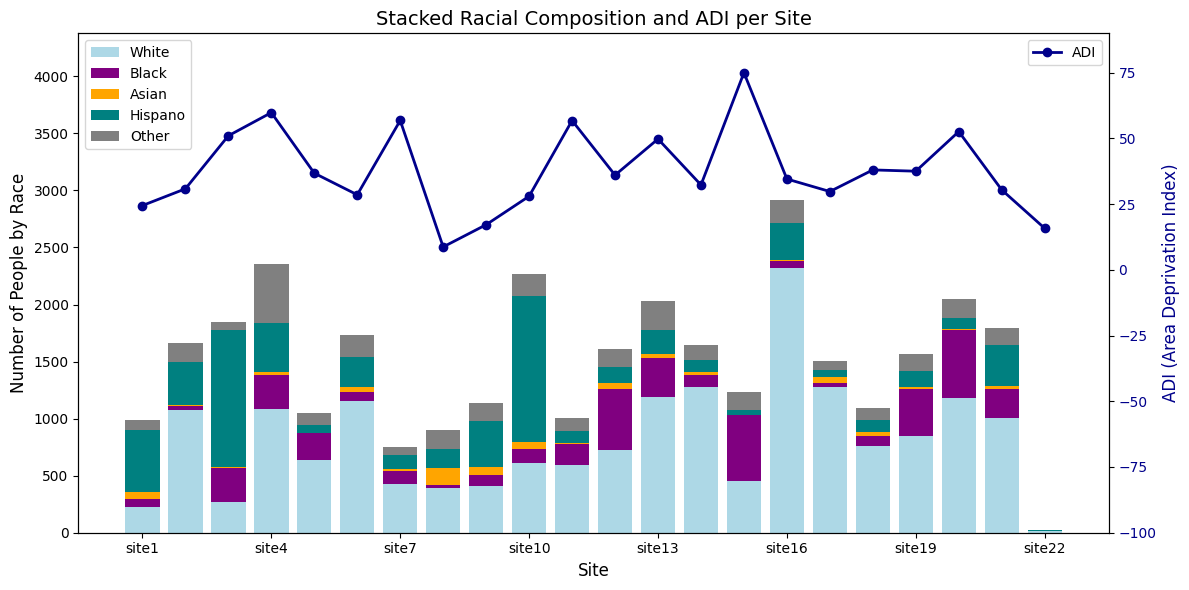

In [119]:
plot_stacked_demographic_counts_with_adi(
    white_num,
    black_num,
    asian_num,
    hispano_num,
    other_num,
    adi_num,
    None)

In [111]:
import numpy as np
import ot
from scipy.spatial.distance import cdist

def get_wasserstein(x, x_hat):
    x = np.array(x)
    x_hat = np.array(x_hat)
    p = np.ones(len(x)) / len(x)
    q = np.ones(len(x_hat)) / len(x_hat)
    M = cdist(x, x_hat, metric="euclidean")
    wass_x = ot.sinkhorn2(p, q, M, reg=0.1, numItermax=500)
    
    return wass_x


def plot_site_vs_overall_wasserstein(df, site_col, x_cols):
    sites = sorted(df[site_col].unique())
    overall_x = df[df[site_col] == 16][x_cols].to_numpy()

    site_distances = []

    for site in sites:
        site_df = df[df[site_col] == site]
        x = site_df[x_cols].to_numpy()
        dist = get_wasserstein(x, overall_x)
        site_distances.append((site, dist))

    # sort by distance descending
    # Plot
    sites_sorted, distances = zip(*site_distances)
    plt.figure(figsize=(12, 6))
    plt.bar(sites_sorted, distances, color="skyblue")
    plt.xlabel("Site")
    plt.ylabel("Wasserstein Distance to Overall")
    plt.title("Wasserstein Distance (per Site vs Overall Distribution)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(site_distances, columns=["site", "wasserstein_distance"])



/Users/gaozhiyuan/.pyenv/versions/3.12.1/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:631: RuntimeWarning: overflow encountered in divide
  v = b / KtransposeU
/Users/gaozhiyuan/.pyenv/versions/3.12.1/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:643: UserWarning: Warning: numerical errors at iteration 319
  warnings.warn("Warning: numerical errors at iteration %d" % ii)


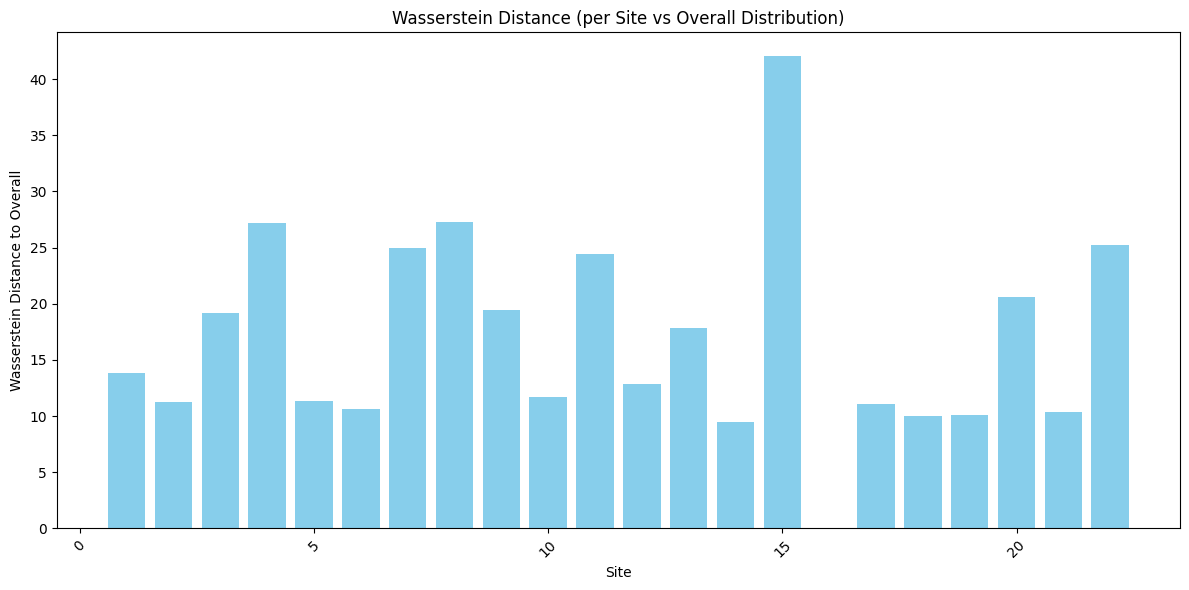

,site,wasserstein_distance
0,1,1.384208e+01
1,2,1.127354e+01
2,3,1.917052e+01
3,4,2.718896e+01
4,5,1.138209e+01
5,6,1.058979e+01
6,7,2.497366e+01
7,8,2.728561e+01
8,9,1.942787e+01
9,10,1.169366e+01


In [112]:
# 例如：你的df里有 site, y 列，以及 x1, x2, x3 作为输入特征
plot_site_vs_overall_wasserstein(
    data,
    site_col="site",
    x_cols=top_vars
)


In [101]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_sitewise_y_distribution_seaborn(data, site_col="site", label_col="y_{t+1}"):
    # Step 1: 计算每个 site 下各类 y 的比例 (%)
    dist_df = (
        data.groupby(site_col)[label_col]
        .value_counts(normalize=True)
        .unstack(fill_value=0)
        .sort_index()
    ) * 100

    # 确保包含 y=0~3
    for col in range(4):
        if col not in dist_df.columns:
            dist_df[col] = 0.0
    dist_df = dist_df[[0, 1, 2, 3]]

    dist_df = dist_df.reset_index().rename(columns={i: f"y={i}" for i in range(4)})

    # Step 2: melt 成 long format
    df_melted = dist_df.melt(id_vars=site_col, var_name="y_class", value_name="proportion")

    # Step 3: Seaborn barplot
    plt.figure(figsize=(14, 6))
    sns.barplot(data=df_melted, x=site_col, y="proportion", hue="y_class", palette="tab10")

    plt.ylabel("Proportion (%)")
    plt.title("Proportion of y_{t+1} by Site")
    plt.xticks(ha="center")
    plt.ylim(0,50)
    plt.legend(title="y_{t+1}")
    plt.tight_layout()
    plt.show()



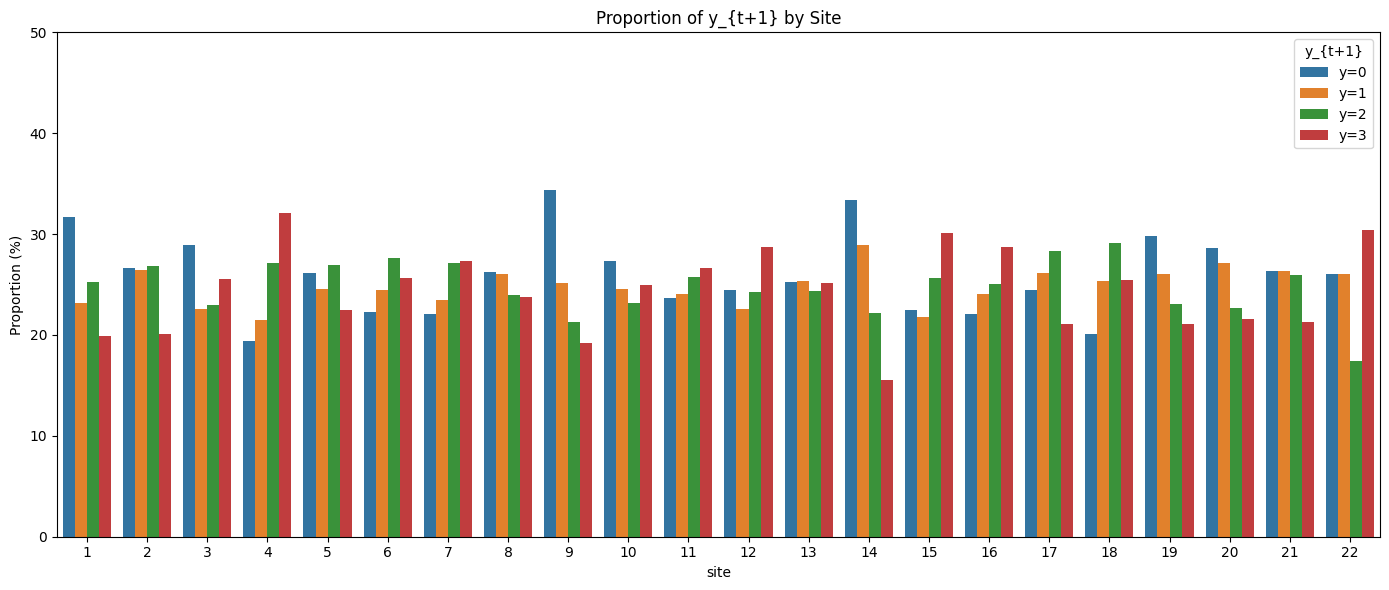

In [102]:
plot_sitewise_y_distribution_seaborn(data)

/var/folders/47/91sqyf453hs814g86jzgnwdh0000gn/T/ipykernel_58279/2976355165.py:26: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(mean_df[site_col], ha="center")


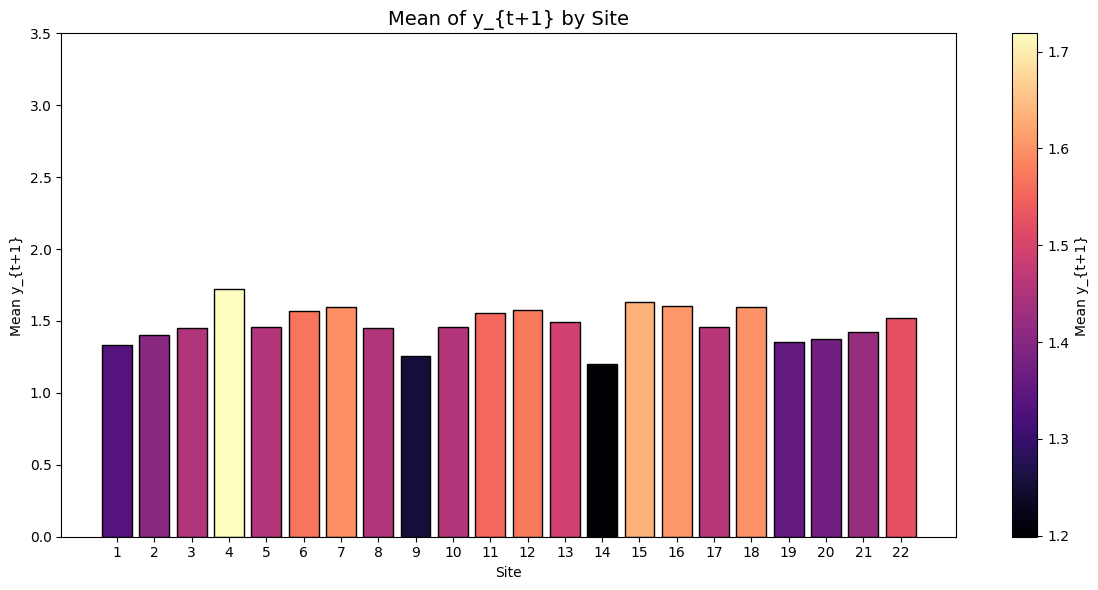

In [110]:

def plot_sitewise_y_mean_with_color(data, site_col="site", label_col="y_{t+1}", cmap_name="magma", vmin=None, vmax=None):
    # 1. 计算 site 的均值
    mean_df = data.groupby(site_col)[label_col].mean().reset_index()

    # 2. 设置颜色映射范围（默认根据数据范围）
    y_min = mean_df[label_col].min() if vmin is None else vmin
    y_max = mean_df[label_col].max() if vmax is None else vmax
    norm = plt.Normalize(y_min, y_max)
    cmap = plt.get_cmap(cmap_name)
    colors = cmap(norm(mean_df[label_col].values))

    # 3. 创建图和轴
    fig, ax = plt.subplots(figsize=(12, 6))
    bars = ax.bar(mean_df[site_col].astype(str), mean_df[label_col], color=colors, edgecolor='black')

    # 4. 添加 colorbar 到 fig 对象中
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax)
    cbar.set_label(f"Mean {label_col}")

    # 5. 图形标签美化
    ax.set_title(f"Mean of {label_col} by Site", fontsize=14)
    ax.set_xlabel("Site")
    ax.set_ylabel(f"Mean {label_col}")
    ax.set_xticklabels(mean_df[site_col], ha="center")
    ax.set_ylim(0, 3.5)
    plt.tight_layout()
    plt.show()

plot_sitewise_y_mean_with_color(data)

/var/folders/47/91sqyf453hs814g86jzgnwdh0000gn/T/ipykernel_72177/895632505.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: dict(zip(x['interview_date'], x['site_id_l'])))


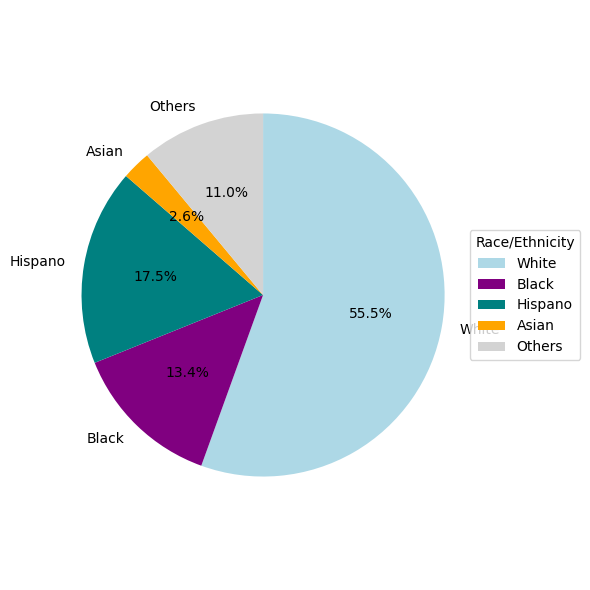

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
site_df = pd.read_csv('abcd_data/abcd_y_lt.csv').iloc[:,[0,2,7]]
testdata = pd.read_csv('abcd_data/test.csv')
testdata = testdata[testdata.columns[~testdata.columns.str.startswith("cbcl")]]
# testdata = testdata.iloc[:,:30]
traindata = pd.read_csv('abcd_data/train.csv')
traindata = traindata[traindata.columns[~traindata.columns.str.startswith("cbcl")]]
# traindata = traindata.iloc[:,:30]
lostcolumns= ["interview_date","site","src_subject_id","y_t", "y_{t+1}", "eventname","race_ethnicity"]
# testdata = pd.read_csv('dealt/test.csv')
# traindara = pd.read_csv('dealt/train.csv')
# lostcolumns= ["interview_date","site","src_subject_id", "y_{t+1}", "eventname"]
site_df['interview_date'] = pd.to_datetime(site_df['interview_date'], errors = 'coerce')
traindata['interview_date'] = pd.to_datetime(traindata['interview_date'], errors = 'coerce')
testdata['interview_date'] = pd.to_datetime(testdata['interview_date'], errors = 'coerce')
site_df['site_id_l'] = site_df['site_id_l'].str[4:].astype(int)
subject_date_site_mapping = (
    site_df.groupby('src_subject_id')
    .apply(lambda x: dict(zip(x['interview_date'], x['site_id_l'])))
    .to_dict()
)
def get_site(row):
    subject_id = row['src_subject_id']
    interview_date = row['interview_date']
    return subject_date_site_mapping.get(subject_id, {}).get(interview_date, None)

traindata['site'] = traindata.apply(get_site, axis=1)
traindata.insert(1, 'site', traindata.pop('site'))
testdata['site'] = traindata.apply(get_site, axis=1)
testdata.insert(1, 'site', testdata.pop('site'))  
testdata = testdata.apply(pd.to_numeric,errors='coerce')
traindata = traindata.apply(pd.to_numeric,errors='coerce')


if testdata.isnull().any().any():
    testdata = testdata.fillna(0)
if traindata.isnull().any().any():
    traindata = traindata.fillna(0)


testdata['white'] = (testdata['race_ethnicity'] == 1).astype(int)
testdata['black'] = (testdata['race_ethnicity'] == 2).astype(int)
testdata['hispano'] = (testdata['race_ethnicity'] == 3).astype(int)
testdata['asian'] = (testdata['race_ethnicity'] == 4).astype(int)
testdata['others'] = (testdata['race_ethnicity'] == 5).astype(int)


traindata['white'] = (traindata['race_ethnicity'] == 1).astype(int)
traindata['black'] = (traindata['race_ethnicity'] == 2).astype(int)
traindata['hispano'] = (traindata['race_ethnicity'] == 3).astype(int)
traindata['asian'] = (traindata['race_ethnicity'] == 4).astype(int)
traindata['others'] = (traindata['race_ethnicity'] == 5).astype(int)


race_mapping = {
    1: 'White',
    2: 'Black',
    3: 'Hispano',
    4: 'Asian',
    5: 'Others'
}
data_train = testdata
data_train['race_ethnicity'] = data_train['race_ethnicity'].replace(race_mapping)

# 统计分布
race_counts = data_train['race_ethnicity'].value_counts()

# 指定颜色顺序（根据 mapping 的顺序）
colors = ['lightblue', 'purple', 'teal', 'orange', 'lightgray']
label_order = ['White', 'Black', 'Hispano', 'Asian', 'Others']

# 统计分布，并按 label_order 重排
race_counts = data_train['race_ethnicity'].value_counts()
race_counts = race_counts.reindex(label_order).fillna(0)  # 防止某些类别没有出现

# 画饼图
plt.figure(figsize=(6,6))
patches, texts, autotexts = plt.pie(
    race_counts.values,
    labels=race_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    colors=colors
)
plt.axis('equal')
plt.legend(patches, race_counts.index, title="Race/Ethnicity", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

In [ ]:
data = pd.concat([traindata, testdata], axis=0, ignore_index=True)

if data.isnull().any().any():
    data = data.fillna(0)

data['white'] = (data['race_ethnicity'] == 1).astype(int)
data['black'] = (data['race_ethnicity'] == 2).astype(int)
data['hispano'] = (data['race_ethnicity'] == 3).astype(int)
data['asian'] = (data['race_ethnicity'] == 4).astype(int)
data['others'] = (data['race_ethnicity'] == 5).astype(int)


data

,src_subject_id,site,y_t,y_{t+1},eventname,demo_sex_v2_1,race_ethnicity,demo_comb_income_v2,parent_highest_education,adi_percentile,...,tfmri_sacsvcg_bcdk_bktsrh,tfmri_ma_alrvn_b_cds_bkslh,tfmri_ma_alrvn_b_cds_bksrh,tfmri_nback_all_339,tfmri_nback_all_373,white,black,hispano,asian,others
0,0.0,6,3.0,3.0,0,1,Black,7,15,26.0,...,0.106272,-0.033646,0.138256,1.345854,1.282947,0,0,0,0,0
1,0.0,6,3.0,3.0,1,1,Black,7,15,26.0,...,0.107173,-0.033646,0.138256,1.345854,1.282947,0,0,0,0,0
2,0.0,6,3.0,3.0,2,1,Black,7,15,26.0,...,0.103645,0.022848,0.035710,-0.106447,-0.041572,0,0,0,0,0
3,0.0,4,3.0,3.0,0,1,White,5,16,66.0,...,0.027437,-0.166263,-0.200856,0.084142,0.165950,0,0,0,0,0
4,0.0,4,3.0,2.0,1,1,White,5,16,66.0,...,0.027437,-0.166263,-0.200856,0.084142,0.165950,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33173,0.0,21,1.0,2.0,2,1,1,10,19,9.0,...,0.001857,-0.248187,-0.235879,-0.053288,-0.055648,1,0,0,0,0
33174,0.0,21,2.0,0.0,3,1,1,10,19,9.0,...,0.001857,-0.248187,-0.235879,-0.053288,-0.055648,1,0,0,0,0
33175,0.0,10,0.0,1.0,0,0,1,9,18,48.0,...,0.377892,0.183260,0.124130,0.049028,0.154370,1,0,0,0,0
33176,0.0,10,1.0,0.0,1,0,1,9,18,48.0,...,0.377892,0.183260,0.124130,0.049028,0.154370,1,0,0,0,0


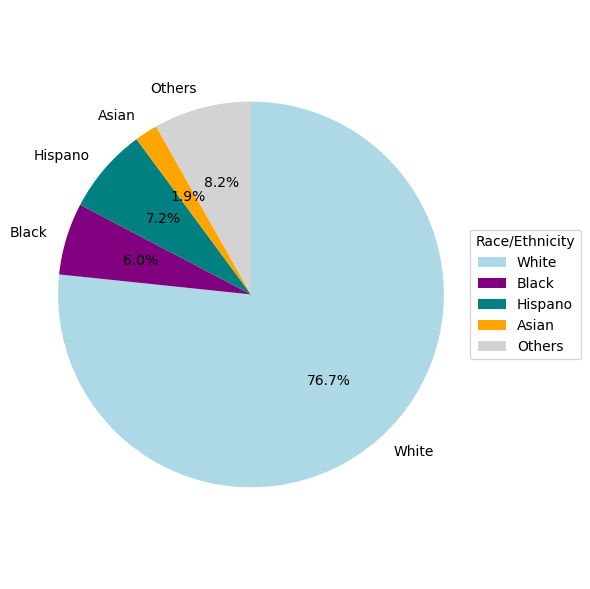

In [23]:

# 统计分布，并按 label_order 重排
race_counts = data[data["site"].isin([14,18])]['race_ethnicity'].value_counts()
race_counts = race_counts.reindex(label_order).fillna(0)  # 防止某些类别没有出现

# 画饼图
plt.figure(figsize=(6,6))
patches, texts, autotexts = plt.pie(
    race_counts.values,
    labels=race_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False,
    colors=colors
)
plt.axis('equal')
plt.legend(patches, race_counts.index, title="Race/Ethnicity", loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()